In [2]:
import os 
import numpy as np
import cv2
from IPython.display import Video, display
import time
import imageio
from ipywidgets import interact, IntSlider, FloatSlider
import matplotlib.pyplot as plt


OPTICAL_FLOW_IDX = 0
FRAMES_IDX = 1
VOXELGRID_IDX = 2

root_path = '../data/ecoco_depthmaps_test/train'
datapoints = []
    
for path in os.listdir(root_path):
    datapoints.append(( os.path.join(root_path, path, "flow"), 
                       os.path.join(root_path, path, "frames"),
                       os.path.join(root_path, path, "VoxelGrid-betweenframes-5") ))


def get_paths_from_folder(folder):
    paths = []
    for f in sorted(os.listdir(folder)):
        if f.endswith(".png") or f.endswith(".npy"):
            paths.append(os.path.join(folder, f))
    return paths

def get_imgs_from_folder(folder):
    imgs = []
    for f in sorted(os.listdir(folder)):
        if f.endswith(".png"):
            im = imageio.imread(os.path.join(folder, f))
            imgs.append(im[:,:])
        elif f.endswith(".npy"):
            im = np.load(os.path.join(folder, f))
            imgs.append(im[:,:])
    return np.array(imgs)

def render_as_video(imgs, output_path="video.mp4"):
    with imageio.get_writer(output_path,
                            format="FFMPEG",
                            fps=5) as vid:
        for im in imgs:
            vid.append_data(im)
    display(Video(output_path, embed=True, width=600, height=400))     

imgs = get_imgs_from_folder(datapoints[0][1])
render_as_video(imgs, "video.mp4")    

C:\Users\levus\AppData\Local\Temp\ipykernel_44268\4274806872.py:35: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  im = imageio.imread(os.path.join(folder, f))
IMAGEIO FFMPEG_WRITER WARNING: input image is not divisible by macro_block_size=16, resizing from (240, 180) to (240, 192) to ensure video compatibility with most codecs and players. To prevent resizing, make your input image divisible by the macro_block_size or set the macro_block_size to 1 (risking incompatibility).


# visualize flow

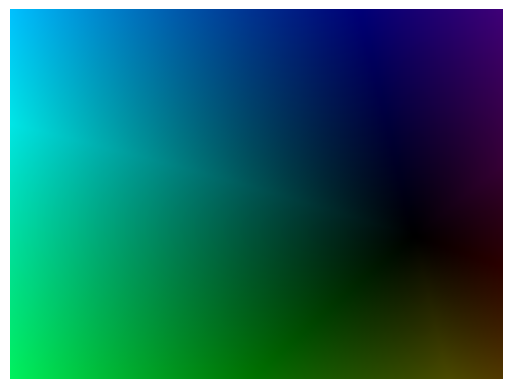

In [3]:
import matplotlib

flow = datapoints[0][OPTICAL_FLOW_IDX]
flow = get_imgs_from_folder(flow)

def flow_to_rgb(flow):
    _, W, H = flow.shape
    hsv = np.zeros((W, H, 3), dtype=np.float32)

    X = flow[0, ...]
    Y = flow[1, ...]
    mag_sq = X**2 + Y**2
    max = np.max(mag_sq) 
    angle = np.atan2(Y, X)
    
    hsv[:, :, 0] = (angle + np.pi) / (2 * np.pi)
    hsv[:, :, 1] = 1.0
    hsv[:, :, 2] = np.sqrt(mag_sq) / np.sqrt(max) if max > 0 else 0.0
    return (matplotlib.colors.hsv_to_rgb(hsv) * 255.0).astype(np.uint8)

    

flow_rgb = flow_to_rgb(flow[0])

plt.imshow(flow_rgb)
plt.axis('off')
plt.show()

In [5]:
rgbs = get_imgs_from_folder(datapoints[0][FRAMES_IDX]) 
flow_rgbs = [flow_to_rgb(el) for el in get_imgs_from_folder(datapoints[0][OPTICAL_FLOW_IDX])]
render_as_video(flow_rgbs, "video_of.mp4")

C:\Users\levus\AppData\Local\Temp\ipykernel_44268\4274806872.py:35: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  im = imageio.imread(os.path.join(folder, f))
IMAGEIO FFMPEG_WRITER WARNING: input image is not divisible by macro_block_size=16, resizing from (240, 180) to (240, 192) to ensure video compatibility with most codecs and players. To prevent resizing, make your input image divisible by the macro_block_size or set the macro_block_size to 1 (risking incompatibility).


In [89]:
with imageio.get_writer("video_stiched.mp4",
                            format="FFMPEG",
                            fps=5) as vid:
        for rgb, flow_rgb in zip(rgbs, flow_rgbs):
            rgb = rgb[..., None]  
            rgb = np.repeat(rgb, 3, axis=2)  # Ensure RGB channels  
            vid.append_data(np.concatenate((rgb, flow_rgb), axis=1))

display(Video("video_rgb+of.mp4", embed=True, width=600, height=400))     

IMAGEIO FFMPEG_WRITER WARNING: input image is not divisible by macro_block_size=16, resizing from (480, 180) to (480, 192) to ensure video compatibility with most codecs and players. To prevent resizing, make your input image divisible by the macro_block_size or set the macro_block_size to 1 (risking incompatibility).


# visualize events

In [92]:
events = get_imgs_from_folder(datapoints[0][VOXELGRID_IDX])

with imageio.get_writer("video_events.mp4",
                            format="FFMPEG",
                            fps=5) as vid:
       for ev in events:
           for frame in ev:
            frame_uint8 = (255 * (frame - np.min(frame)) / (np.max(frame) - np.min(frame))).astype(np.uint8) 
            vid.append_data( frame_uint8 )  
               

display(Video("video_events.mp4", embed=True, width=600, height=400))     

IMAGEIO FFMPEG_WRITER WARNING: input image is not divisible by macro_block_size=16, resizing from (240, 180) to (240, 192) to ensure video compatibility with most codecs and players. To prevent resizing, make your input image divisible by the macro_block_size or set the macro_block_size to 1 (risking incompatibility).


# show all 3

In [98]:
def render_as_video_stich(datapoint, output_path="video_stiched.mp4"):
    
    flow_folder, rgb_folder, of_folder = datapoint
    print(rgb_folder, flow_folder, of_folder)
    
    rgbs, flow_rgbs, events = [], [], []
    rgbs = get_imgs_from_folder(rgb_folder)
    flows = get_imgs_from_folder(flow_folder)
    print(flows.shape)
    
    flow_rgbs = [flow_to_rgb(el) for el in flows]
    events = get_imgs_from_folder(of_folder)
    
    i = 0    
    with imageio.get_writer(output_path,
                            format="FFMPEG",
                            fps=5) as vid:
        for ev_vox in events: 
            for evs in ev_vox:
                evs = (255 * (evs - np.min(evs)) / (np.max(evs) - np.min(evs))).astype(np.uint8) 
                evs = np.repeat(evs[..., None], 3, axis=2)
                rgb = rgbs[i][..., None]
                rgb = np.repeat(rgb, 3, axis=2)
                vid.append_data(np.concatenate((rgb, evs, flow_rgbs[i]), axis=1))
            i += 1

    display(Video(output_path, embed=True, width=600, height=400))
    
render_as_video_stich(datapoints[0], "video_stiched.mp4")

./ecoco_depthmaps_test/train\sequence_0000000000\frames ./ecoco_depthmaps_test/train\sequence_0000000000\flow ./ecoco_depthmaps_test/train\sequence_0000000000\VoxelGrid-betweenframes-5
(55, 2, 180, 240)


C:\Users\levus\AppData\Local\Temp\ipykernel_46408\3444503699.py:28: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  im = imageio.imread(os.path.join(folder, f))
IMAGEIO FFMPEG_WRITER WARNING: input image is not divisible by macro_block_size=16, resizing from (720, 180) to (720, 192) to ensure video compatibility with most codecs and players. To prevent resizing, make your input image divisible by the macro_block_size or set the macro_block_size to 1 (risking incompatibility).


# Some utils

In [100]:
frames = get_paths_from_folder(datapoints[0][FRAMES_IDX])
optical_flows = get_paths_from_folder(datapoints[0][OPTICAL_FLOW_IDX])
events = get_paths_from_folder(datapoints[0][VOXELGRID_IDX])

print(frames)
print(optical_flows)
print(events)

['./ecoco_depthmaps_test/train\\sequence_0000000000\\frames\\frame_0000000000.png', './ecoco_depthmaps_test/train\\sequence_0000000000\\frames\\frame_0000000001.png', './ecoco_depthmaps_test/train\\sequence_0000000000\\frames\\frame_0000000002.png', './ecoco_depthmaps_test/train\\sequence_0000000000\\frames\\frame_0000000003.png', './ecoco_depthmaps_test/train\\sequence_0000000000\\frames\\frame_0000000004.png', './ecoco_depthmaps_test/train\\sequence_0000000000\\frames\\frame_0000000005.png', './ecoco_depthmaps_test/train\\sequence_0000000000\\frames\\frame_0000000006.png', './ecoco_depthmaps_test/train\\sequence_0000000000\\frames\\frame_0000000007.png', './ecoco_depthmaps_test/train\\sequence_0000000000\\frames\\frame_0000000008.png', './ecoco_depthmaps_test/train\\sequence_0000000000\\frames\\frame_0000000009.png', './ecoco_depthmaps_test/train\\sequence_0000000000\\frames\\frame_0000000010.png', './ecoco_depthmaps_test/train\\sequence_0000000000\\frames\\frame_0000000011.png', './

In [105]:
from collections import defaultdict

frame_sizes = []
counts = defaultdict(int)

for i in range(len(datapoints)):
    frames = get_paths_from_folder(datapoints[i][FRAMES_IDX])
    counts[len(frames)] += 1
    
print(counts)

defaultdict(<class 'int'>, {56: 88, 58: 378, 52: 6, 57: 240, 59: 143, 55: 53, 53: 13, 54: 16, 51: 2, 50: 4, 48: 2, 37: 1, 44: 1, 47: 1})


In [ ]:
print(f"Size of dataset : {len(datapoints)}")
print("histogram of frame counts per datapoint: ")
for count, freq in counts.items():
    print(f"{count} frames: {freq} datapoints")

Size of dataset : 948


In [103]:
print(datapoints)

[('./ecoco_depthmaps_test/train\\sequence_0000000000\\flow', './ecoco_depthmaps_test/train\\sequence_0000000000\\frames', './ecoco_depthmaps_test/train\\sequence_0000000000\\VoxelGrid-betweenframes-5'), ('./ecoco_depthmaps_test/train\\sequence_0000000001\\flow', './ecoco_depthmaps_test/train\\sequence_0000000001\\frames', './ecoco_depthmaps_test/train\\sequence_0000000001\\VoxelGrid-betweenframes-5'), ('./ecoco_depthmaps_test/train\\sequence_0000000002\\flow', './ecoco_depthmaps_test/train\\sequence_0000000002\\frames', './ecoco_depthmaps_test/train\\sequence_0000000002\\VoxelGrid-betweenframes-5'), ('./ecoco_depthmaps_test/train\\sequence_0000000003\\flow', './ecoco_depthmaps_test/train\\sequence_0000000003\\frames', './ecoco_depthmaps_test/train\\sequence_0000000003\\VoxelGrid-betweenframes-5'), ('./ecoco_depthmaps_test/train\\sequence_0000000004\\flow', './ecoco_depthmaps_test/train\\sequence_0000000004\\frames', './ecoco_depthmaps_test/train\\sequence_0000000004\\VoxelGrid-betweenf